In [1]:
import numpy as np
import matplotlib.pyplot as plt
import struct

In [6]:
import os

folder = r"C:\Users\agarw\Downloads\MNIST"

print("Folder exists:", os.path.exists(folder))
print("Files found:", os.listdir(folder) if os.path.exists(folder) else "Folder not found")

Folder exists: False
Files found: Folder not found


In [7]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/vaagar/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte
/kaggle/input/datasets/vaagar/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte


In [11]:
import numpy as np
import struct
import os

# Replace this with the actual folder path from Step 2
folder = "/kaggle/input/datasets/vaagar/mnist-dataset"

def load_images(filename):
    path = os.path.join(folder, filename)

    with open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)

    return images.reshape(count, rows, cols)


def load_labels(filename):
    path = os.path.join(folder, filename)

    with open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)

    return labels


X_train = load_images("train-images.idx3-ubyte")
y_train = load_labels("train-labels.idx1-ubyte")

X_test = load_images("t10k-images.idx3-ubyte")
y_test = load_labels("t10k-labels.idx1-ubyte")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


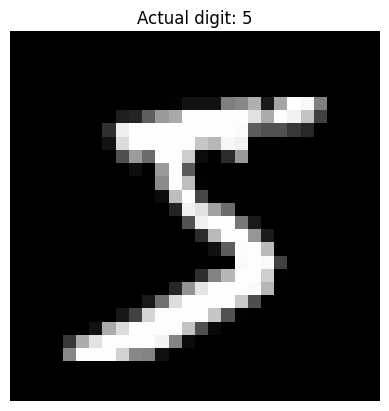

In [12]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0], cmap="gray")
plt.title(f"Actual digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [13]:
# Flatten each image: 28 x 28 = 784 pixels
X_train = X_train.reshape(60000, 784).astype(np.float32)
X_test = X_test.reshape(10000, 784).astype(np.float32)

# Normalize pixel values
X_train /= 255.0
X_test /= 255.0

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

Training data: (60000, 784)
Test data: (10000, 784)


In [14]:
# Network architecture
input_size = 784
hidden_size = 64
output_size = 10

np.random.seed(42)

# Weights and biases: input -> hidden
W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

# Weights and biases: hidden -> output
W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

learning_rate = 0.1
epochs = 10
batch_size = 64

In [15]:
def relu(z):
    return np.maximum(0, z)


def softmax(z):
    # Improves numerical stability
    z = z - np.max(z, axis=1, keepdims=True)

    exp_z = np.exp(z)

    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [16]:
# Use a subset for the first experiment
X = X_train[:10000]
y = y_train[:10000]

for epoch in range(epochs):

    # Shuffle the examples each epoch
    indices = np.random.permutation(len(X))
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    total_loss = 0
    batches = 0

    for start in range(0, len(X), batch_size):

        xb = X_shuffled[start:start + batch_size]
        yb = y_shuffled[start:start + batch_size]
        m = len(xb)

        # ---------- Forward propagation ----------

        z1 = xb @ W1 + b1
        a1 = relu(z1)

        z2 = a1 @ W2 + b2
        probs = softmax(z2)

        # ---------- Calculate loss ----------

        correct_probs = probs[np.arange(m), yb]
        loss = -np.mean(np.log(correct_probs + 1e-12))

        total_loss += loss
        batches += 1

        # ---------- Backpropagation ----------

        dz2 = probs.copy()
        dz2[np.arange(m), yb] -= 1
        dz2 /= m

        dW2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ W2.T
        dz1 = da1 * (z1 > 0)

        dW1 = xb.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # ---------- Gradient descent ----------

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    # Check accuracy after each epoch
    hidden = relu(X @ W1 + b1)
    train_probs = softmax(hidden @ W2 + b2)
    predictions = np.argmax(train_probs, axis=1)

    accuracy = np.mean(predictions == y)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / batches:.4f} | "
        f"Accuracy: {accuracy * 100:.2f}%"
    )

Epoch 1/10 | Loss: 1.5272 | Accuracy: 82.16%
Epoch 2/10 | Loss: 0.4957 | Accuracy: 87.74%
Epoch 3/10 | Loss: 0.3694 | Accuracy: 90.68%
Epoch 4/10 | Loss: 0.3225 | Accuracy: 90.95%
Epoch 5/10 | Loss: 0.2952 | Accuracy: 89.91%
Epoch 6/10 | Loss: 0.2721 | Accuracy: 92.53%
Epoch 7/10 | Loss: 0.2532 | Accuracy: 93.35%
Epoch 8/10 | Loss: 0.2343 | Accuracy: 93.20%
Epoch 9/10 | Loss: 0.2195 | Accuracy: 93.49%
Epoch 10/10 | Loss: 0.2035 | Accuracy: 94.60%


In [17]:
# Forward propagation on test data
hidden_test = relu(X_test @ W1 + b1)
test_probs = softmax(hidden_test @ W2 + b2)

# Select the digit with the highest probability
test_predictions = np.argmax(test_probs, axis=1)

# Compare predictions with correct labels
test_accuracy = np.mean(test_predictions == y_test)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test accuracy: 91.86%


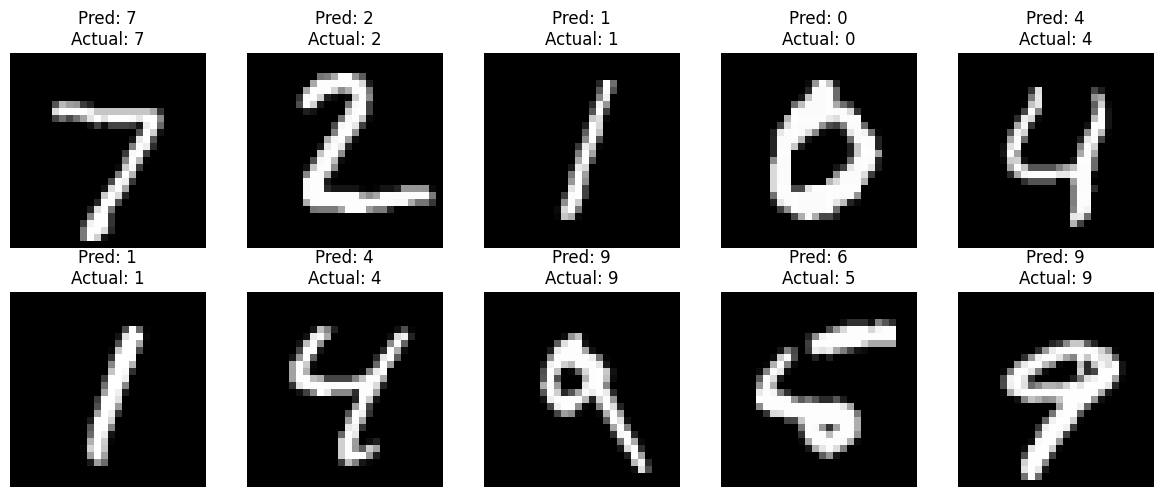

In [18]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Pred: {test_predictions[i]}\n"
        f"Actual: {y_test[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()